# SHOW failure cases 

- result from seed-42 cases are selected. 
- Green  is the ground-truth mask; red is the regenerated predicted mask.


**8 cases**
1. classification N, sgementation Y, ground truth Y
2. classification N, sgementation Y, ground truth N
3. classification Y, sgementation N, ground truth Y
4. classification Y, sgementation N, ground truth N
5. classification Y, sgementation Y, ground truth N
6. classification N, sgementation N, ground truth Y
7. classification Y but wrong tumor type, sgementation Y, ground truth Y 
8. classification Y, sgementation Y but poor/severe DICE/IoU, ground truth Y

In [6]:
from functools import lru_cache
from pathlib import Path
import json, sys
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from PIL import Image
import torch

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'src/models.py').exists())
ART = ROOT / 'cloud_artifacts/lopo-seed42'
DATA = ROOT / 'brisc2025'
sys.path.insert(0, str(ROOT / 'src'))
from models import UNet

In [ ]:
rows = []
for plane in ('axial', 'coronal', 'sagittal'):
    exp = f'leave_{plane}_out_seed42'; base = ART / 'results' / exp
    fusion = pd.DataFrame(json.loads((base / 'reports/heldout_fusion.json').read_text())['samples'])
    seg = pd.DataFrame(json.loads((base / 'predictions/segmentation_heldout/run.json').read_text())['predictions'])
    rows.append(fusion.merge(seg[['filename', 'mask_dice', 'mask_iou']], on='filename').assign(experiment=exp))
df = pd.concat(rows, ignore_index=True)
df['predicted_confidence'] = df.apply(lambda r: r[f'probability_{r.predicted_class}'], axis=1)

used = set()
def take(label, query, score, ascending):
    pool = df.query(query).sort_values(score, ascending=ascending)
    row = next(r for _, r in pool.iterrows() if (r.experiment, r.filename) not in used)
    used.add((row.experiment, row.filename))
    return row.to_dict() | {'failure': label}

specs = [
 ('Case 1: classifier presence FN', "plane_label=='axial' and not classification_says_tumor and segmentation_says_tumor and ground_truth_tumor", 'mask_dice', False),
 ('Case 2: Segmenter presence FP', "plane_label=='coronal' and not classification_says_tumor and segmentation_says_tumor and not ground_truth_tumor", 'predicted_mask_area_fraction', False),
 ('Case 3: Segmenter presence FN', "plane_label=='sagittal' and classification_says_tumor and not segmentation_says_tumor and ground_truth_tumor", 'mask_dice', True),
 ('Case 4: classifier presence FP', "plane_label=='axial' and classification_says_tumor and not segmentation_says_tumor and not ground_truth_tumor", 'classification_tumor_probability', False),
 ('Case 5: joint FP', "plane_label=='coronal' and classification_says_tumor and segmentation_says_tumor and not ground_truth_tumor", 'predicted_mask_area_fraction', False),
 ('Case 6: joint presence FN', "plane_label=='sagittal' and not classification_says_tumor and not segmentation_says_tumor and ground_truth_tumor", 'mask_dice', False),
 ('Case 7: wrong tumor subtype', "plane_label=='axial' and classification_says_tumor and segmentation_says_tumor and ground_truth_tumor and predicted_class != tumor_label",'mask_dice', False),
 ('Case 8: severe spatial segmentation error', "plane_label=='axial' and classification_says_tumor and segmentation_says_tumor and ground_truth_tumor and predicted_class == tumor_label", 'mask_dice', True),
]
selected = pd.DataFrame([take(*spec) for spec in specs])
selected[['failure', 'plane_label', 'tumor_label', 'predicted_class', 'mask_dice', 'filename']]

,failure,plane_label,tumor_label,predicted_class,mask_dice,filename
0,Case 1: classifier FN,axial,glioma,glioma,9.263729e-01,brisc2025_train_00341_gl_ax_t1.jpg
1,Case 2: segmentation FP,coronal,no_tumor,no_tumor,2.750275e-10,brisc2025_train_03137_no_co_t1.jpg
2,Case 3: segmentation FN,sagittal,glioma,glioma,2.677376e-10,brisc2025_train_00978_gl_sa_t1.jpg
3,Case 4: classifier presence FP,axial,no_tumor,meningioma,1.000000e+00,brisc2025_train_02571_no_ax_t1.jpg
4,Case 5: joint FP,coronal,no_tumor,meningioma,5.232862e-10,brisc2025_train_02843_no_co_t1.jpg
5,Case 6: joint presence FN,sagittal,pituitary,no_tumor,8.719723e-01,brisc2025_train_04936_pi_sa_t1.jpg
6,Case 7: wrong tumor subtype,axial,pituitary,meningioma,9.550056e-01,brisc2025_train_03561_pi_ax_t1.jpg
7,Case 8: severe spatial segmentation error,axial,meningioma,meningioma,1.188778e-10,brisc2025_train_01382_me_ax_t1.jpg


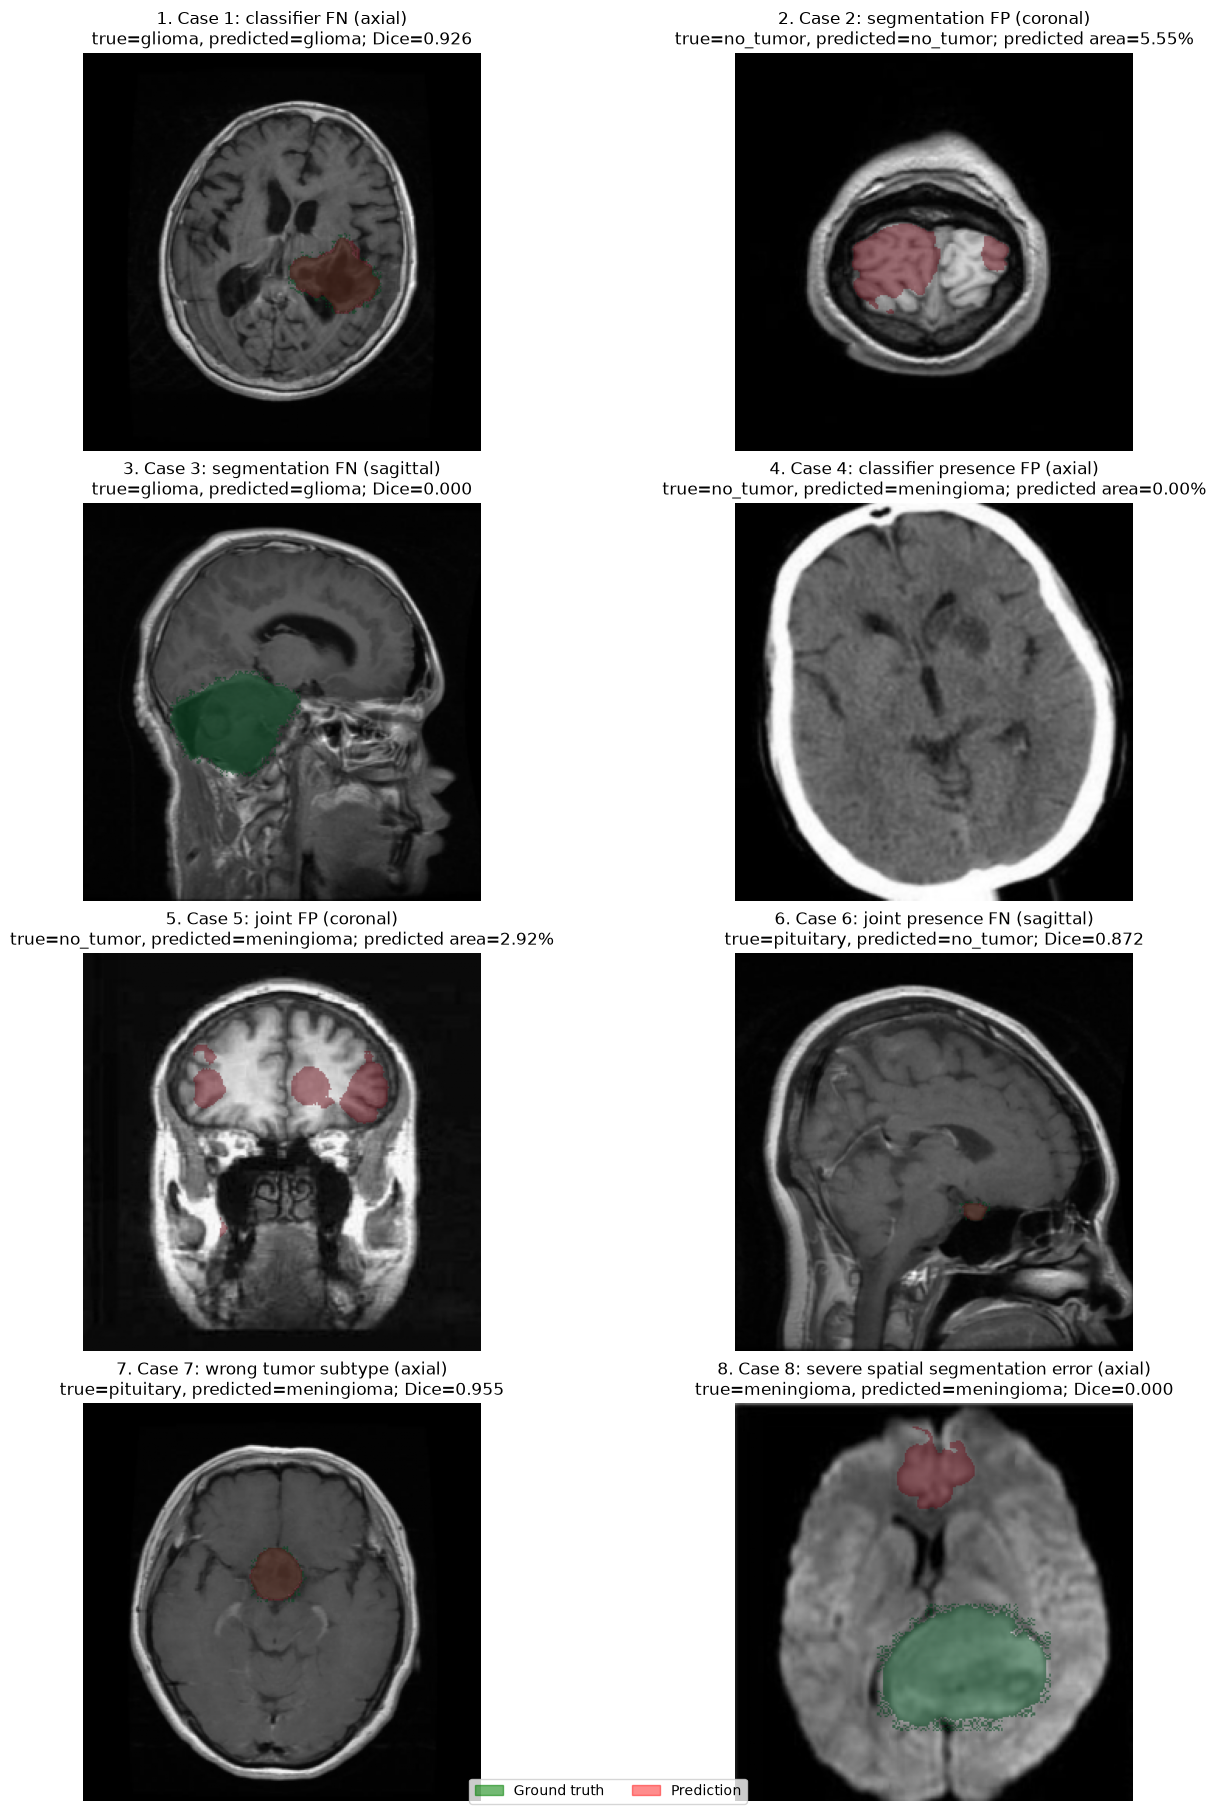

In [8]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

@lru_cache
def segmenter(plane):
    state = torch.load(ART / 'checkpoints' / f'leave_{plane}_out_seed42/segmentation/best.pt', map_location=device, weights_only=True)
    cfg = state['config']; model = UNet(1, 1, bool(cfg.get('bilinear', False))).to(device)
    model.load_state_dict(state['model_state_dict']); model.eval()
    return model, int(cfg.get('image_size', 256)), float(cfg.get('threshold', .5))

def masks(row):
    model, size, threshold = segmenter(row.plane_label)
    image_path = DATA / Path(row.relative_path.replace('\\', '/'))
    mask_path = DATA / 'segmentation_task/train/masks' / row.filename.replace('.jpg', '.png')
    image = np.asarray(Image.open(image_path).convert('L').resize((size, size), Image.Resampling.BILINEAR), dtype=np.float32)
    truth = np.asarray(Image.open(mask_path).convert('L').resize((size, size), Image.Resampling.NEAREST)) > 0 if mask_path.exists() else np.zeros((size, size), bool)
    x = torch.from_numpy(image / 127.5 - 1)[None, None].to(device)
    with torch.inference_mode():
        prediction = torch.sigmoid(model(x))[0, 0].cpu().numpy() >= threshold
    return image, truth, prediction

fig, axes = plt.subplots(4, 2, figsize=(13, 18), constrained_layout=True)
for number, (ax, (_, row)) in enumerate(zip(axes.flat, selected.iterrows()), 1):
    image, truth, prediction = masks(row)
    ax.imshow(image, cmap='gray')
    ax.imshow(np.ma.masked_where(~truth, truth), cmap='Greens', alpha=.55, vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~prediction, prediction), cmap='Reds', alpha=.45, vmin=0, vmax=1)
    metric = f'Dice={row.mask_dice:.3f}' if row.ground_truth_tumor else f'predicted area={100 * row.predicted_mask_area_fraction:.2f}%'
    ax.set_title(f'{number}. {row.failure} ({row.plane_label})\ntrue={row.tumor_label}, predicted={row.predicted_class}; {metric}')
    ax.axis('off')
fig.legend(handles=[Patch(color='green', alpha=.55, label='Ground truth'), Patch(color='red', alpha=.45, label='Prediction')], loc='lower center', ncol=2)
plt.show()

## All-plane versus LOPO statistics

Counts include the percentage of each evaluation set. Wrong-subtype and severe-spatial rows can overlap the presence-error categories.

In [ ]:
from IPython.display import display
ALL = Path.home() / 'Downloads/brainTumor-cloud/all_planes_seed42'
c = pd.DataFrame(json.loads((ALL / 'predictions/classification_validation/run.json').read_text())['predictions'])
s = pd.DataFrame(json.loads((ALL / 'predictions/segmentation_validation/run.json').read_text())['predictions'])
t = json.loads((ALL / 'reports/thresholds.json').read_text())
all_plane = c.merge(s[['filename', 'predicted_mask_area_fraction', 'mask_dice', 'mask_iou']], on='filename')
all_plane['classification_tumor_probability'] = 1 - all_plane.no_tumor_probability
all_plane['classification_says_tumor'] = all_plane.classification_tumor_probability >= t['classification_threshold']
all_plane['segmentation_says_tumor'] = all_plane.predicted_mask_area_fraction >= t['area_threshold']
all_plane['ground_truth_tumor'] = all_plane.tumor_label != 'no_tumor'
all_plane['experiment'] = 'all_planes_seed42'

def flags(x):
    c, s, t = x.classification_says_tumor, x.segmentation_says_tumor, x.ground_truth_tumor
    return {
      'Classifier presence FN': ~c & s & t, 'Segmenter presence FP': ~c & s & ~t,
      'Segmenter presence FN': c & ~s & t, 'Classifier presence FP': c & ~s & ~t,
      'Joint presence FP': c & s & ~t, 'Joint presence FN': ~c & ~s & t,
      'Wrong tumor subtype': c & s & t & (x.predicted_class != x.tumor_label),
      'Severe spatial error (Dice < 0.10)': t & (x.mask_dice < .10)}

def counts(x):
    return pd.Series({k: f'{v.sum():,} ({v.mean():.1%})' for k, v in flags(x).items()})

display(pd.concat({'All-plane validation': counts(all_plane), 'LOPO held-out': counts(df)}, axis=1))

,All-plane validation,LOPO held-out
Classifier presence FN,6 (0.6%),253 (5.1%)
Segmenter presence FP,26 (2.6%),233 (4.7%)
Segmenter presence FN,43 (4.3%),295 (5.9%)
Classifier presence FP,0 (0.0%),40 (0.8%)
Joint presence FP,0 (0.0%),17 (0.3%)
Joint presence FN,0 (0.0%),52 (1.0%)
Wrong tumor subtype,3 (0.3%),506 (10.1%)
Severe spatial error (Dice < 0.10),35 (3.5%),665 (13.3%)


## Tumor types that are hardest to detect

Classification recall measures correct subtype prediction. Dice is shown only for tumor-positive classes. The per-plane LOPO tables reveal errors hidden by pooled averages.

In [10]:
def tumor_metrics(x):
    recall = x.assign(correct=x.predicted_class == x.tumor_label).groupby('tumor_label').correct.mean()
    dice = x[x.tumor_label != 'no_tumor'].groupby('tumor_label').mask_dice.mean()
    return pd.DataFrame({'classification recall': recall, 'mean Dice': dice})

display(pd.concat({'All-plane validation': tumor_metrics(all_plane), 'LOPO held-out': tumor_metrics(df)}, axis=1).round(3))
display(df.assign(correct=df.predicted_class == df.tumor_label).pivot_table(index='tumor_label', columns='plane_label', values='correct', aggfunc='mean').round(3).rename_axis('LOPO classification recall'))
display(df[df.tumor_label != 'no_tumor'].pivot_table(index='tumor_label', columns='plane_label', values='mask_dice', aggfunc='mean').round(3).rename_axis('LOPO mean Dice'))

All-plane validation                   LOPO held-out          
            classification recall mean Dice classification recall mean Dice
tumor_label                                                                
glioma                      1.000     0.631                 0.939     0.519
meningioma                  0.985     0.877                 0.868     0.787
no_tumor                    0.981       NaN                 0.903       NaN
pituitary                   1.000     0.813                 0.597     0.491

plane_label,axial,coronal,sagittal
LOPO classification recall,,,
glioma,0.962,0.984,0.851
meningioma,0.832,0.871,0.896
no_tumor,0.866,0.848,0.975
pituitary,0.153,0.925,0.639


plane_label,axial,coronal,sagittal
LOPO mean Dice,,,
glioma,0.439,0.550,0.574
meningioma,0.666,0.871,0.818
pituitary,0.222,0.682,0.522


## Representative all-plane validation failures

These four cases provide a within-domain reference for the LOPO gallery above.

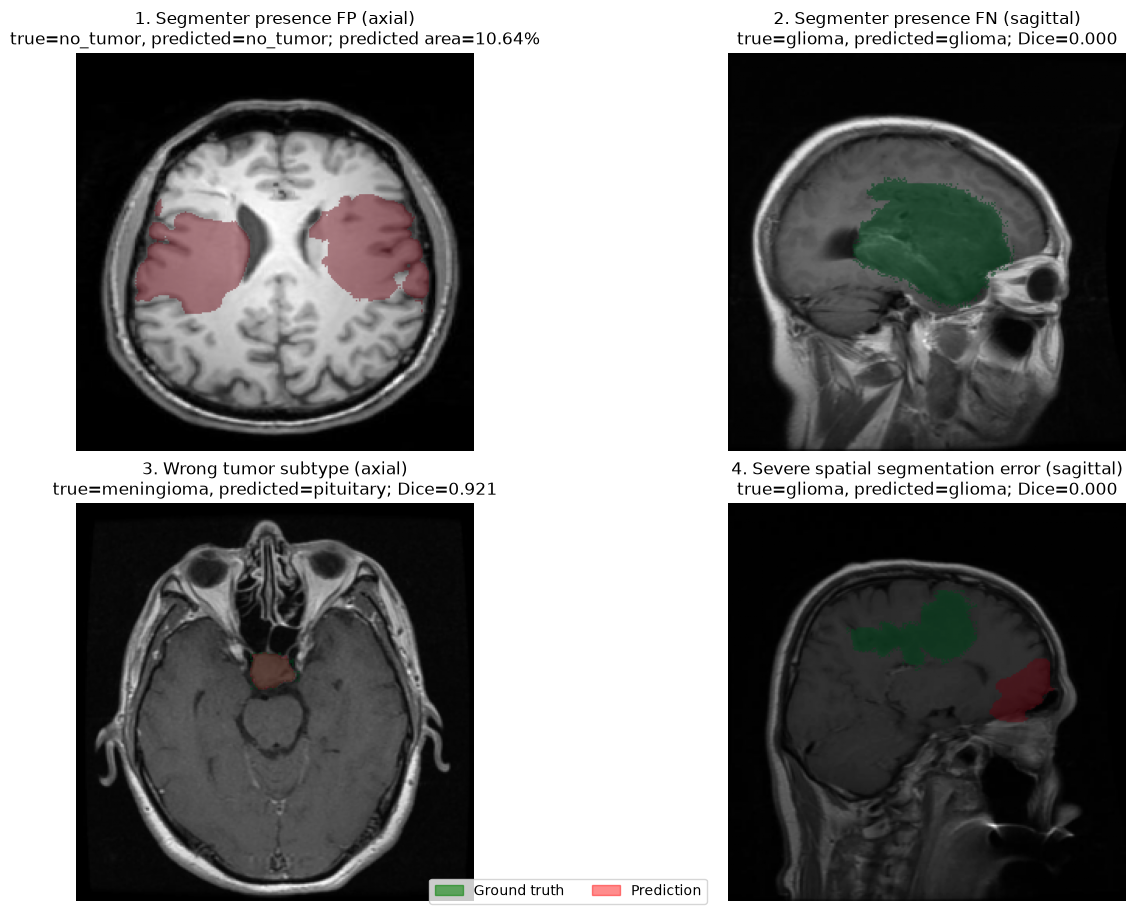

In [11]:
all_specs = [
 ('Segmenter presence FP', "not classification_says_tumor and segmentation_says_tumor and not ground_truth_tumor", 'predicted_mask_area_fraction', False),
 ('Segmenter presence FN', "classification_says_tumor and not segmentation_says_tumor and ground_truth_tumor", 'mask_dice', True),
 ('Wrong tumor subtype', "classification_says_tumor and segmentation_says_tumor and ground_truth_tumor and predicted_class != tumor_label", 'mask_dice', False),
 ('Severe spatial segmentation error', "classification_says_tumor and segmentation_says_tumor and ground_truth_tumor and predicted_class == tumor_label", 'mask_dice', True)]
all_cases = pd.DataFrame([all_plane.query(q).sort_values(score, ascending=asc).iloc[0].to_dict() | {'failure': label} for label, q, score, asc in all_specs])

state = torch.load(ALL / 'segmentation/best.pt', map_location=device, weights_only=True); cfg = state['config']
all_model = UNet(1, 1, bool(cfg.get('bilinear', False))).to(device)
all_model.load_state_dict(state['model_state_dict']); all_model.eval()

def all_masks(row):
    size = int(cfg.get('image_size', 256)); image_path = DATA / Path(row.relative_path.replace('\\', '/'))
    mask_path = DATA / 'segmentation_task/train/masks' / row.filename.replace('.jpg', '.png')
    image = np.asarray(Image.open(image_path).convert('L').resize((size, size), Image.Resampling.BILINEAR), dtype=np.float32)
    truth = np.asarray(Image.open(mask_path).convert('L').resize((size, size), Image.Resampling.NEAREST)) > 0 if mask_path.exists() else np.zeros((size, size), bool)
    with torch.inference_mode(): pred = torch.sigmoid(all_model(torch.from_numpy(image / 127.5 - 1)[None, None].to(device)))[0, 0].cpu().numpy() >= float(cfg.get('threshold', .5))
    return image, truth, pred

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for n, (ax, (_, row)) in enumerate(zip(axes.flat, all_cases.iterrows()), 1):
    image, truth, pred = all_masks(row); ax.imshow(image, cmap='gray')
    ax.imshow(np.ma.masked_where(~truth, truth), cmap='Greens', alpha=.55, vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~pred, pred), cmap='Reds', alpha=.45, vmin=0, vmax=1)
    metric = f'Dice={row.mask_dice:.3f}' if row.ground_truth_tumor else f'predicted area={100 * row.predicted_mask_area_fraction:.2f}%'
    ax.set_title(f'{n}. {row.failure} ({row.plane_label})\ntrue={row.tumor_label}, predicted={row.predicted_class}; {metric}'); ax.axis('off')
fig.legend(handles=[Patch(color='green', alpha=.55, label='Ground truth'), Patch(color='red', alpha=.45, label='Prediction')], loc='lower center', ncol=2)
plt.show()

## Confirmation across seeds 42, 123, and 456

The tables below distinguish stable failure patterns from seed-specific examples. Rates use each run's own validation-calibrated presence thresholds.

In [12]:
EXTRA = Path.home() / 'Downloads/brainTumor-cloud/brainTumor-seeds-123-456/results'

def run_dir(seed, name):
    if seed == 42: return ALL if name == 'all_planes' else ART / 'results' / f'{name}_seed42'
    return EXTRA / f'{name}_seed{seed}'

def load_eval(seed, name, split):
    base = run_dir(seed, name)
    c = pd.DataFrame(json.loads((base / f'predictions/classification_{split}/run.json').read_text())['predictions'])
    s = pd.DataFrame(json.loads((base / f'predictions/segmentation_{split}/run.json').read_text())['predictions'])
    t = json.loads((base / 'reports/thresholds.json').read_text())
    x = c.merge(s[['filename', 'predicted_mask_area_fraction', 'mask_dice', 'mask_iou']], on='filename')
    x['classification_tumor_probability'] = 1 - x.no_tumor_probability
    x['classification_says_tumor'] = x.classification_tumor_probability >= t['classification_threshold']
    x['segmentation_says_tumor'] = x.predicted_mask_area_fraction >= t['area_threshold']
    x['ground_truth_tumor'] = x.tumor_label != 'no_tumor'
    return x.assign(seed=seed)

runs = []
for seed in (42, 123, 456):
    runs.append(load_eval(seed, 'all_planes', 'validation').assign(configuration='All-plane validation'))
    for plane in ('axial', 'coronal', 'sagittal'):
        runs.append(load_eval(seed, f'leave_{plane}_out', 'heldout').assign(configuration='LOPO held-out'))
multi = pd.concat(runs, ignore_index=True)

rates = pd.DataFrame({(cfg, seed): {k: v.mean() for k, v in flags(g).items()}
                      for (cfg, seed), g in multi.groupby(['configuration', 'seed'])}).T
display((100 * rates).round(2).rename_axis(['configuration', 'seed']).style.set_caption('Failure rate by seed (%)'))
mean, sd = rates.groupby(level=0).mean().T * 100, rates.groupby(level=0).std().T * 100
display(pd.concat([mean.add_suffix(' mean (%)'), sd.add_suffix(' SD (%)')], axis=1).round(2))

lopo3 = multi[multi.configuration == 'LOPO held-out'].copy()
lopo3['correct'] = lopo3.predicted_class == lopo3.tumor_label
lopo3['positive_dice'] = lopo3.mask_dice.where(lopo3.tumor_label != 'no_tumor')
per_seed = lopo3.groupby(['seed', 'plane_label', 'tumor_label']).agg(recall=('correct', 'mean'), dice=('positive_dice', 'mean'))
summary = per_seed.groupby(['plane_label', 'tumor_label']).agg(['mean', 'std'])
fmt = lambda m, s: '—' if pd.isna(m) else f'{m:.3f} ± {s:.3f}'
recall = summary.apply(lambda r: fmt(r[('recall', 'mean')], r[('recall', 'std')]), axis=1).unstack(0)
dice = summary.apply(lambda r: fmt(r[('dice', 'mean')], r[('dice', 'std')]), axis=1).unstack(0)
display(recall.rename_axis('LOPO classification recall (mean ± SD)'))
display(dice.rename_axis('LOPO positive Dice (mean ± SD)'))

lopo3['joint_fn'] = ~lopo3.classification_says_tumor & ~lopo3.segmentation_says_tumor & lopo3.ground_truth_tumor
joint = lopo3.groupby(['seed', 'plane_label']).joint_fn.mean().groupby('plane_label').agg(['mean', 'std'])
display(joint.apply(lambda r: fmt(r['mean'], r['std']), axis=1).to_frame('Joint FN rate'))

,All-plane validation mean (%),LOPO held-out mean (%),All-plane validation SD (%),LOPO held-out SD (%)
Classifier presence FN,0.20,4.95,0.35,1.63
Segmenter presence FP,2.60,4.59,1.80,0.52
Segmenter presence FN,3.77,7.47,0.55,2.66
Classifier presence FP,0.00,1.01,0.00,0.32
Joint presence FP,0.00,0.48,0.00,0.16
Joint presence FN,0.00,1.89,0.00,0.74
Wrong tumor subtype,0.77,8.58,0.45,1.36
Severe spatial error (Dice < 0.10),3.37,13.20,0.12,1.67


plane_label,axial,coronal,sagittal
LOPO classification recall (mean ± SD),,,
glioma,0.969 ± 0.006,0.972 ± 0.011,0.846 ± 0.018
meningioma,0.864 ± 0.059,0.924 ± 0.048,0.893 ± 0.009
no_tumor,0.762 ± 0.171,0.934 ± 0.075,0.979 ± 0.009
pituitary,0.154 ± 0.026,0.932 ± 0.028,0.644 ± 0.108


plane_label,axial,coronal,sagittal
LOPO positive Dice (mean ± SD),,,
glioma,0.505 ± 0.058,0.587 ± 0.035,0.572 ± 0.014
meningioma,0.741 ± 0.067,0.864 ± 0.007,0.837 ± 0.018
no_tumor,—,—,—
pituitary,0.357 ± 0.117,0.671 ± 0.047,0.488 ± 0.043


,Joint FN rate
plane_label,
axial,0.036 ± 0.014
coronal,0.000 ± 0.000
sagittal,0.021 ± 0.009
